# Introduction

Social media platforms generate large amounts of data through user interactions such as likes, comments, shares, impressions, and watch time. Analyzing this engagement data will helps the organizations to understand audience behavior, measure content performance, and make data-driven decisions. This study focuses on applying Python-based data analytics techniques to a social media engagement dataset.

Using libraries such as NumPy, Pandas, Matplotlib, and Seaborn, the dataset will be cleaned, transformed, analyzed, and visualized to uncover meaningful patterns and trends. The insights obtained from this analysis can help improve content strategies, increase user engagement, and enhance overall social media performance.

# ❖	Task 1 — Data Import & Setup

○	Import CSV using Pandas

○	Check/convert data types

○	Convert date columns to datetime

○	Use NumPy arrays for basic array operations


In [2]:
import pandas as pd
from google.colab import files
uploaded = files.upload()

import pandas as pd
df = pd.read_csv("social_media_engagement_5000.csv")

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [5]:
print(df.dtypes)

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [7]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [9]:
print(df.columns)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')


In [12]:
df['posted_at'] = pd.to_datetime(df['posted_at'], dayfirst=True, errors='coerce')

print(df['posted_at'].dtype)

datetime64[ns]


In [13]:
df[['age','likes','comments','shares','posted_at']].dtypes

,0
age,float64
likes,float64
comments,float64
shares,float64
posted_at,datetime64[ns]


In [17]:
likes_arr = np.array(df['likes'])
print("Mean Likes:", np.mean(likes_arr))
print("Maximum Likes:", np.max(likes_arr))
print("Minimum Likes:", np.min(likes_arr))
print("Total Likes:", np.sum(likes_arr))

Mean Likes: nan
Maximum Likes: nan
Minimum Likes: nan
Total Likes: nan


# Notes:

First, we import Pandas and NumPy libraries.

pd.read_csv() is used to load the social media dataset.

head() displays the first 5 rows of data.

info() shows column names, data types, and missing values.

pd.to_datetime() converts the Date column into datetime format for easier date analysis.

A NumPy array is created from the Likes column.

NumPy functions such as mean(), max(), and min() are used to perform basic array operations and analyze engagement data.

# ❖	Task 2 — Data Cleaning

●	 Cleaning Missing Data

■	Detect missing values (isnull(), isna())

■	Handle using: dropna(), fillna(), median/mode, forward/backward-fill


In [18]:
print(df.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [19]:
print(df.isna().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [20]:
df_drop = df.dropna()

print(df_drop.shape)

(4162, 19)


In [21]:
df['age'] = df['age'].fillna(df['age'].median())

In [22]:
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])

In [23]:
df.ffill(inplace=True)
df.bfill(inplace=True)

# Notes:
Used isnull().sum() to identify missing values in each column.

Used isna().sum() to verify the missing values.

Applied dropna() to remove rows containing null values.

Filled missing numerical values using the column median with fillna(median()).

Filled missing categorical values using the most frequent value with fillna(mode()[0]).

Used ffill() (forward fill) to replace missing values with the previous valid value.

Used bfill() (backward fill) to replace missing values with the next valid value.

Verified that missing values were handled successfully by checking the dataset again with isnull().sum().


●	Duplicate Handling

■	Identify & remove duplicates


In [24]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


●	Data Formatting

■	Fix incorrect data types

■	Standardize categories (e.g., gender labels)

■	Correct unrealistic values in likes, comments, shares

●	 Feature Cleaning

■	Extract hashtag count

■	Clean sentiment labels


In [34]:
df['age']=df['age'].fillna(df['age'].median())

In [35]:
df['likes']=df['likes'].fillna(round(df['likes'].median()))

In [36]:
df['comments']=df['comments'].fillna(df['comments'].median())
df['shares']=df['shares'].fillna(df['shares'].median())

In [37]:
df['gender']=df['gender'].fillna(df['gender'].mode()[0])

In [38]:
df['sentiment']=df['sentiment'].fillna(df['sentiment'].mode()[0])

In [40]:
print("Gender:", df['gender'].unique())
print("Country:", df['country'].unique())
print("Post type:", df['post_type'].unique())
print("Post category:", df['post_category'].unique())
print("Device type:", df['device_type'].unique())
print("Sentiment:", df['sentiment'].unique())

Gender: ['female' 'male' 'other']
Country: ['Brazil' 'UK' 'France' 'Canada' 'Japan' 'Australia' 'India' 'UAE'
 'Germany' 'USA']
Post type: ['image' 'reel' 'text' 'video']
Post category: ['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']
Device type: ['mobile' 'tablet' 'desktop']
Sentiment: ['negative' 'positive' 'neutral']


In [41]:
df[['likes', 'comments', 'shares']].describe()

,likes,comments,shares
count,5000.0,5000.0,5000.0
mean,10100.7218,1503.5046,1002.0586
std,5781.646631,869.443836,579.106821
min,10.0,0.0,0.0
25%,5073.5,760.0,497.75
50%,10093.5,1498.0,1010.5
75%,15113.0,2258.0,1500.25
max,19998.0,2999.0,1999.0


In [42]:
print("Negative likes:", (df['likes'] < 0).sum())
print("Negative comments:", (df['comments'] < 0).sum())
print("Negative shares:", (df['shares'] < 0).sum())

Negative likes: 0
Negative comments: 0
Negative shares: 0


In [43]:
df['hashtag_count'] = df['hashtags'].fillna('').apply(
    lambda x: len(str(x).split(','))
    if str(x).strip() != '' else 0
)

print(df[['hashtags', 'hashtag_count']].head())

                hashtags  hashtag_count
0  #foodie #travel #love              1
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              1
4                #travel              1


# Notes:

Checked for duplicate records in the dataset

Used df.duplicated() to identify rows that were repeated.

drop_duplicates() removes all duplicate rows from the dataset.

The cleaned dataset is stored back in df.

Running duplicated().sum() again confirms that no duplicate records remain.

Used astype('Int64') to convert age, likes, comments, and shares into integer format.

Used pd.to_datetime() to convert the posted_at column into datetime format.

dayfirst=True interprets dates in day-month-year format.

errors='coerce' converts invalid dates into NaT.

Used unique() to identify different gender labels.

str.strip() removes extra spaces.

str.lower() converts all values to lowercase.

replace() standardizes labels such as M → Male and F → Female.

Checked for unrealistic negative value

Used median values to fill missing records.

Created a new column called hashtag_count.

Missing hashtag values were replaced with an empty string.

Split hashtags based on commas.

Counted the number of hashtags in each post.

Used unique() to inspect sentiment categories.

Removed unwanted spaces using str.strip().

Converted all labels to lowercase using str.lower().


❖	Task 3 — Data Exploration using Pandas


●	View dataset structure using head(), tail(), shape, and columns.



In [44]:
print(df.head())

   user_id  age  gender country  post_id post_type post_category  likes  \
0    25795   43  female  Brazil   496713     image       fitness   7011   
1    10860   33    male  Brazil   157326      reel          food  11750   
2    86820   32  female      UK   109864      text          food   4862   
3    64886   51   other  France   848877      text       fitness   5350   
4    16265   34   other      UK   449706     image       fitness  12682   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0       354    1157            5726             44650 2022-12-17   
1      2606    1807            5947             80216 2023-06-02   
2       344     955            6946             44858 2023-05-07   
3      1083    1049             229             70455 2023-02-12   
4      2735    1300            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile  negative  #foodie

In [45]:
print(df.tail())

      user_id  age  gender    country  post_id post_type post_category  likes  \
4995    59500   44    male  Australia   441541     video     education  16210   
4996    22100   38   other        UAE   677076      reel     education  16924   
4997    67021   63  female        USA   273595      text        travel  13487   
4998    29800   13  female    Germany   785644     video       fitness  16894   
4999    73400   54   other      Japan   712252      text        travel  14830   

      comments  shares  watch_time_sec  impression_count  posted_at  \
4995      2013    1837            6190             42977 2022-06-25   
4996      2734    1583            7764             34196 2022-11-18   
4997      2734     167            7466             23680 2023-04-06   
4998      1289    1713            4991             89013 2022-05-16   
4999       503    1798            3743             14234 2023-03-04   

      follower_count  is_verified device_type sentiment  \
4995          646147       

In [46]:
print("Shape of dataset:", df.shape)

Shape of dataset: (5000, 20)


In [47]:
print(df.columns)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')


●	Check data types and info with info() and dtypes.

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   Int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   Int64         
 8   comments          5000 non-null   Int64         
 9   shares            5000 non-null   Int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [49]:
print(df.dtypes)

user_id                      int64
age                          Int64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                        Int64
comments                     Int64
shares                       Int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
hashtag_count                int64
dtype: object


●	Generate summary statistics using describe().

In [50]:
print(df.describe())

            user_id        age        post_id        likes    comments  \
count   5000.000000     5000.0    5000.000000       5000.0      5000.0   
mean   54561.890800    38.4404  548042.909000   10100.7218   1503.5046   
min    10055.000000       13.0  100068.000000         10.0         0.0   
25%    32309.500000       26.0  322543.500000       5073.5       760.0   
50%    54374.500000       38.0  548077.500000      10093.5      1498.0   
75%    77180.500000       51.0  771574.500000      15113.0      2258.0   
max    99963.000000       64.0  999455.000000      19998.0      2999.0   
std    26090.370121  14.687151  260646.957267  5781.646631  869.443836   

           shares  watch_time_sec  impression_count  \
count      5000.0     5000.000000       5000.000000   
mean    1002.0586     4014.503200      50013.732800   
min           0.0        0.000000        105.000000   
25%        497.75     2017.750000      24988.250000   
50%        1010.5     4034.500000      49934.500000   
75%

●	Analyze categorical distributions using value_counts(), unique(), and nunique().

In [51]:
print(df['gender'].unique())

print("Number of unique genders:", df['gender'].nunique())

print(df['gender'].value_counts())

['female' 'male' 'other']
Number of unique genders: 3
gender
male      1849
other     1581
female    1570
Name: count, dtype: int64


●	Create a correlation matrix for numeric fields.

In [52]:
numeric_df = df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()
print(corr_matrix)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.028945 -0.034024  0.013534   
age              -0.006688  1.000000 -0.013153 -0.036672 -0.004658  0.012708   
post_id           0.020051 -0.013153  1.000000  0.018269 -0.008969  0.001371   
likes             0.028945 -0.036672  0.018269  1.000000 -0.020425  0.006045   
comments         -0.034024 -0.004658 -0.008969 -0.020425  1.000000  0.007534   
shares            0.013534  0.012708  0.001371  0.006045  0.007534  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.005733 -0.016789  0.016494   
impression_count  0.015326  0.013322 -0.007709  0.000630 -0.008705 -0.005523   
follower_count    0.010124 -0.024894 -0.002844 -0.024152 -0.017114 -0.007200   
engagement_rate  -0.004282  0.008039  0.010139  0.093173  0.000151  0.021675   
hashtag_count          NaN       NaN       NaN       NaN       NaN       NaN   

                  watch_time_sec  impre

●	Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).

In [53]:
avg_likes = df.groupby('post_type')['likes'].mean()

print(avg_likes)

post_type
image    10101.903769
reel     10039.093531
text     10100.661847
video    10164.125714
Name: likes, dtype: Float64


In [54]:
country_impressions = df.groupby('country')['impression_count'].mean()

print(country_impressions)

country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64


Notes:

1. View Dataset Structure

Used head() to display the first 5 rows.
Used tail() to display the last 5 rows.
Used shape to check the number of rows and columns.
Used columns to view all column names.

2. Check Data Types and Information

Used info() to view dataset summary and non-null values.
Used dtypes to check the data type of each column.
Verified numeric, categorical, and datetime columns.

3. Generate Summary Statistics

Used describe() to calculate count, mean, standard deviation, minimum, maximum, and quartile values.
Analyzed the distribution of numerical variables.

4. Analyze Categorical Distributions

Used unique() to view distinct category values.
Used nunique() to count unique categories.
Used value_counts() to calculate the frequency of each category.

5. Create Correlation Matrix

Selected numeric columns using select_dtypes().
Used corr() to calculate correlations between numerical variables.
Identified relationships among engagement metrics.

6. Summarize Data Using groupby()

Used groupby('post_type')['likes'].mean() to calculate average likes by post type.
Used groupby('country')['impression_count'].mean() to calculate average impressions by country.
Compared performance metrics across different categories.

# ❖	Task 4 — Data Wrangling

●	Use merge, concat, or join if combining DataFrames.

●	Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count.

●	Perform groupby summaries by post_type, country, and sentiment.


In [59]:
df['engagement_score'] = df['likes'] + df['comments'] + df['shares']

In [60]:
df[['likes', 'comments', 'shares', 'engagement_score']].head()

,likes,comments,shares,engagement_score
0,7011,354,1157,8522
1,11750,2606,1807,16163
2,4862,344,955,6161
3,5350,1083,1049,7482
4,12682,2735,1300,16717


In [61]:
df['log_likes'] = np.log1p(df['likes'])
df['log_comments'] = np.log1p(df['comments'])
df['log_shares'] = np.log1p(df['shares'])

In [62]:
df[['likes', 'log_likes','comments', 'log_comments','shares', 'log_shares']].head()

,likes,log_likes,comments,log_comments,shares,log_shares
0,7011,8.855378,354,5.872118,1157,7.05445
1,11750,9.371694,2606,7.865955,1807,7.499977
2,4862,8.489411,344,5.843544,955,6.862758
3,5350,8.585039,1083,6.988413,1049,6.956545
4,12682,9.448018,2735,7.914252,1300,7.170888


In [63]:
df.groupby('post_type')['engagement_score'].mean()

,engagement_score
post_type,
image,12645.004812
reel,12529.476228
text,12607.199197
video,12646.386122


In [64]:
df.groupby('country')['engagement_score'].mean()

,engagement_score
country,
Australia,12773.137931
Brazil,12396.958333
Canada,12635.444444
France,12844.256048
Germany,12626.028571
India,12609.527103
Japan,12573.902542
UAE,12723.5666
UK,12324.894523


In [65]:
df.groupby('sentiment')['engagement_score'].mean()

,engagement_score
sentiment,
negative,12680.788093
neutral,12499.319365
positive,12645.166804


# Notes:

Used concat(), merge(), or join() to combine DataFrames when necessary.

Created a new engagement_score by adding likes, comments, and shares.

Applied log1p() to create log-transformed metrics and reduce skewness.

Used groupby('post_type') to analyze average likes by post type.

Used groupby('country') to analyze average impressions by country.

Used groupby('sentiment') to analyze average engagement rates by sentiment.

Used these summaries to identify content performance patterns and audience behavior.

# ❖	Task 5 — Statistical Analysis

Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers:


In [68]:
columns = ['likes', 'comments', 'shares',
           'watch_time_sec', 'engagement_rate',
           'follower_count']

for col in columns:
    print("\n", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])


 likes
Mean: 10100.7218
Median: 10093.5
Mode: 12031

 comments
Mean: 1503.5046
Median: 1498.0
Mode: 2934

 shares
Mean: 1002.0586
Median: 1010.5
Mode: 397

 watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916

 engagement_rate
Mean: 0.9643560291583999
Median: 0.2538959065
Mode: 0.006362909

 follower_count
Mean: 393698.2248
Median: 388982.0
Mode: 497502


In [69]:
for col in columns:
    print("\n", col)
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())


 likes
Standard Deviation: 5781.646630637078
Variance: 33427437.761557072

 comments
Standard Deviation: 869.4438356187818
Variance: 755932.5832954992

 shares
Standard Deviation: 579.1068206367298
Variance: 335364.7097079816

 watch_time_sec
Standard Deviation: 2308.096459042085
Variance: 5327309.26424261

 engagement_rate
Standard Deviation: 5.318029222661535
Variance: 28.281434813082043

 follower_count
Standard Deviation: 230927.88453461014
Variance: 53327687855.63023


In [70]:
for col in columns:
    print("\n", col)
    print("25th Percentile:", df[col].quantile(0.25))
    print("50th Percentile:", df[col].quantile(0.50))
    print("75th Percentile:", df[col].quantile(0.75))


 likes
25th Percentile: 5073.5
50th Percentile: 10093.5
75th Percentile: 15113.0

 comments
25th Percentile: 760.0
50th Percentile: 1498.0
75th Percentile: 2258.0

 shares
25th Percentile: 497.75
50th Percentile: 1010.5
75th Percentile: 1500.25

 watch_time_sec
25th Percentile: 2017.75
50th Percentile: 4034.5
75th Percentile: 6020.25

 engagement_rate
25th Percentile: 0.14578108750000002
50th Percentile: 0.2538959065
75th Percentile: 0.504793702

 follower_count
25th Percentile: 194480.0
50th Percentile: 388982.0
75th Percentile: 589744.25


# Notes:

Calculated the mean to find the average value of each metric.

Calculated the median to find the middle value.

Calculated the mode to identify the most common value.

Computed standard deviation to measure data variability.

Computed variance to determine data dispersion.

Calculated 25th, 50th, and 75th percentiles to understand data distribution.

Performed all statistical calculations for likes, comments, shares, watch_time_sec, engagement_rate, and follower_count.

# ❖	Task 6 — Data Visualization


●	Matplotlib

○	Scatter: likes vs impressions

○	Line: daily engagement trend

○	Bar: posts by category

○	Pie: gender distribution

○	Histogram: age

○	Box: engagement rate


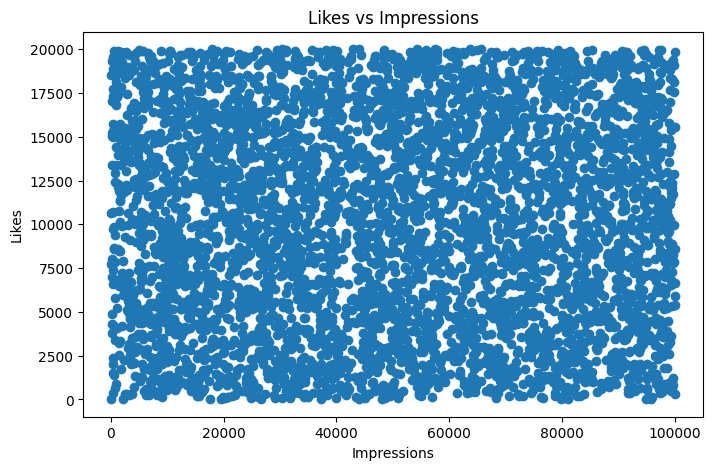

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(df['impression_count'], df['likes'])
plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')
plt.show()

# Notes:

Used a scatter plot to visualize the relationship between likes and impressions.

Impressions are plotted on the x-axis and likes on the y-axis.

Helps identify whether higher impressions lead to more likes.

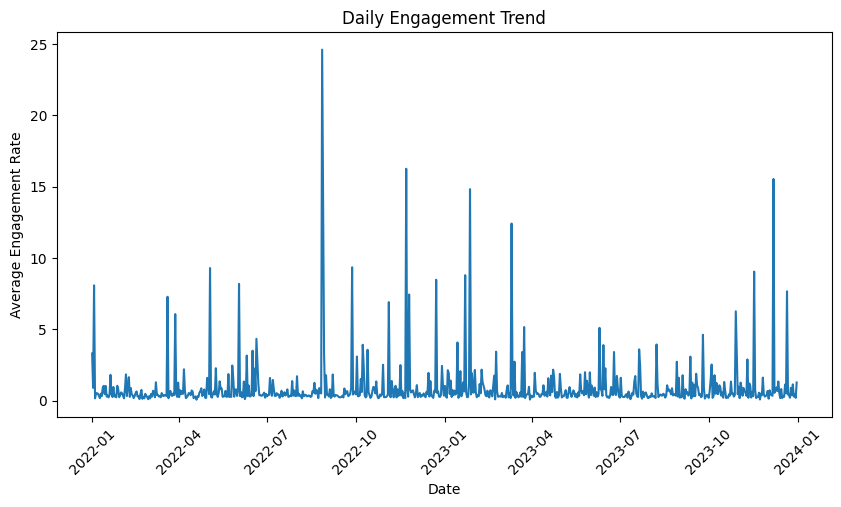

In [72]:
daily_engagement = df.groupby(df['posted_at'].dt.date)['engagement_rate'].mean()

plt.figure(figsize=(10,5))
plt.plot(daily_engagement.index, daily_engagement.values)
plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')
plt.title('Daily Engagement Trend')
plt.xticks(rotation=45)
plt.show()

# Notes:

Grouped data by date.

Calculated average engagement rate for each day.

Used a line plot to show engagement trends over time.

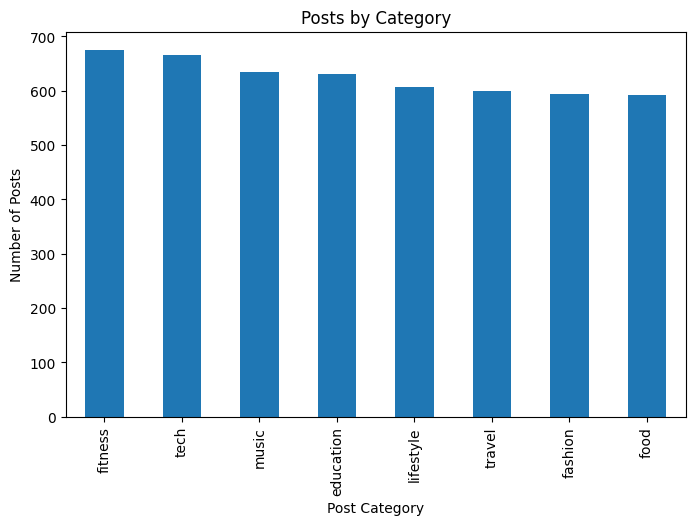

In [73]:
category_count = df['post_category'].value_counts()

plt.figure(figsize=(8,5))
category_count.plot(kind='bar')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.title('Posts by Category')
plt.show()

# Notes:

Counted posts in each category.

Used a bar chart to compare category frequencies.

Helps identify the most common content category.

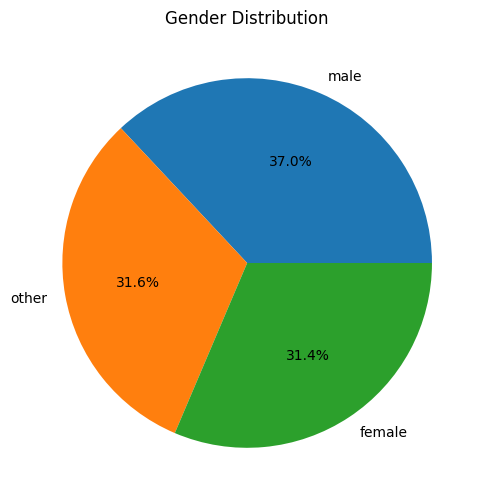

In [74]:
gender_count = df['gender'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(gender_count,
        labels=gender_count.index,
        autopct='%1.1f%%')
plt.title('Gender Distribution')
plt.show()

Notes:

Calculated gender frequencies.

Displayed proportions using a pie chart.

Shows the percentage distribution of users by gender.

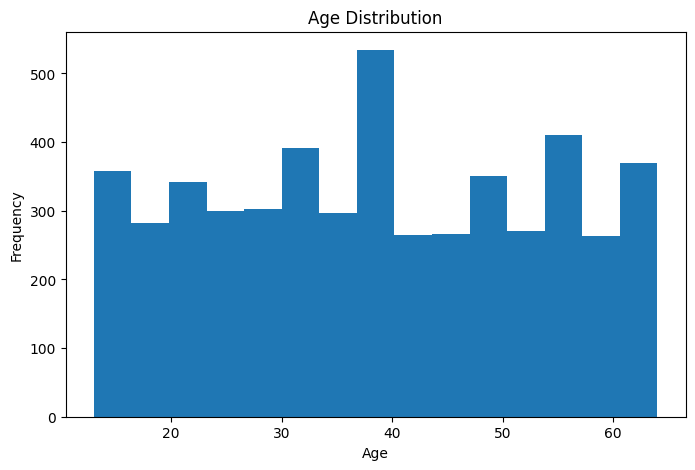

In [75]:
plt.figure(figsize=(8,5))
plt.hist(df['age'], bins=15)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

# Notes:

Used a histogram to visualize age distribution.

Bins divide the ages into intervals.

Helps understand user age patterns.

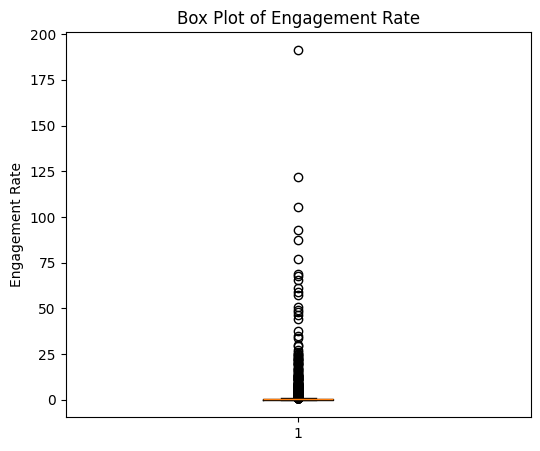

In [76]:
plt.figure(figsize=(6,5))
plt.boxplot(df['engagement_rate'].dropna())
plt.ylabel('Engagement Rate')
plt.title('Box Plot of Engagement Rate')
plt.show()

# Notes:

Used a box plot to visualize the distribution of engagement rates.

Helps detect outliers and measure data spread.

Displays median and quartiles.

●	Seaborn

○	Count plot: post type

○	Bar plot: avg likes by category

○	Violin: followers vs sentiment

○	Pair plot: numeric features

○	Heatmap: correlation matrix

○	Swarm plot: engagement vs device


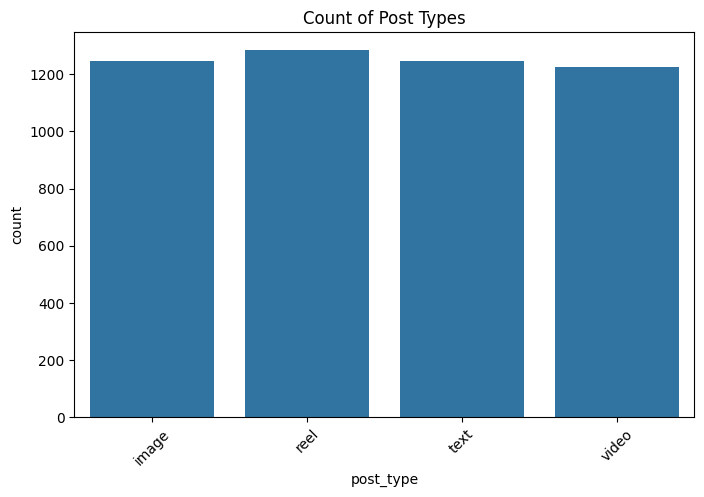

In [77]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='post_type')
plt.title("Count of Post Types")
plt.xticks(rotation=45)
plt.show()

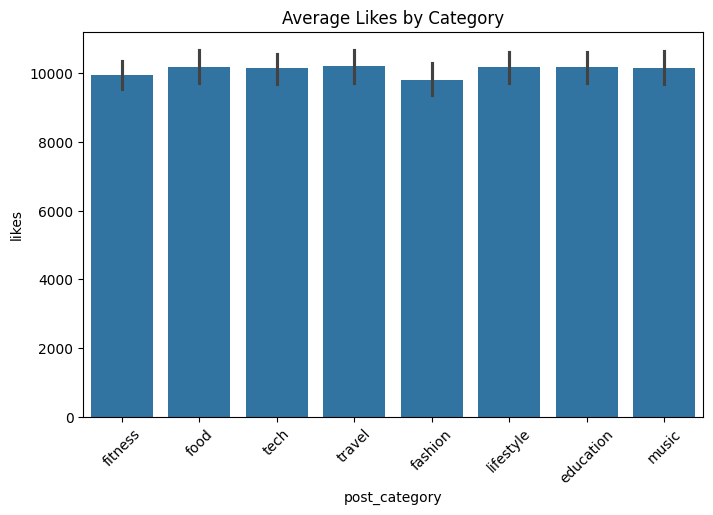

In [78]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='post_category', y='likes', estimator='mean')
plt.title("Average Likes by Category")
plt.xticks(rotation=45)
plt.show()

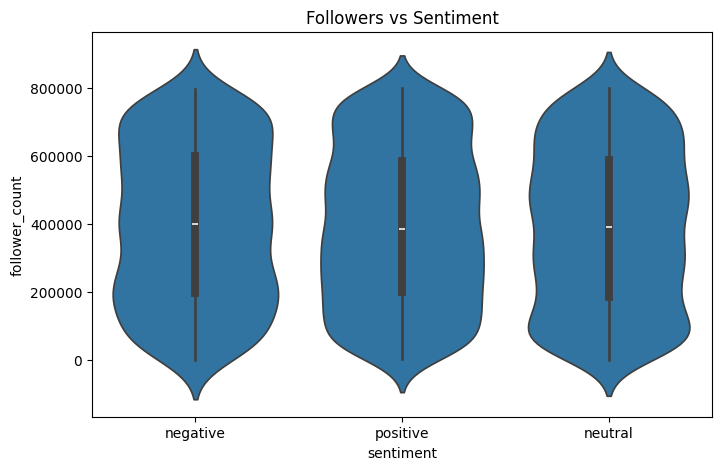

In [79]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x='sentiment', y='follower_count')
plt.title("Followers vs Sentiment")
plt.show()

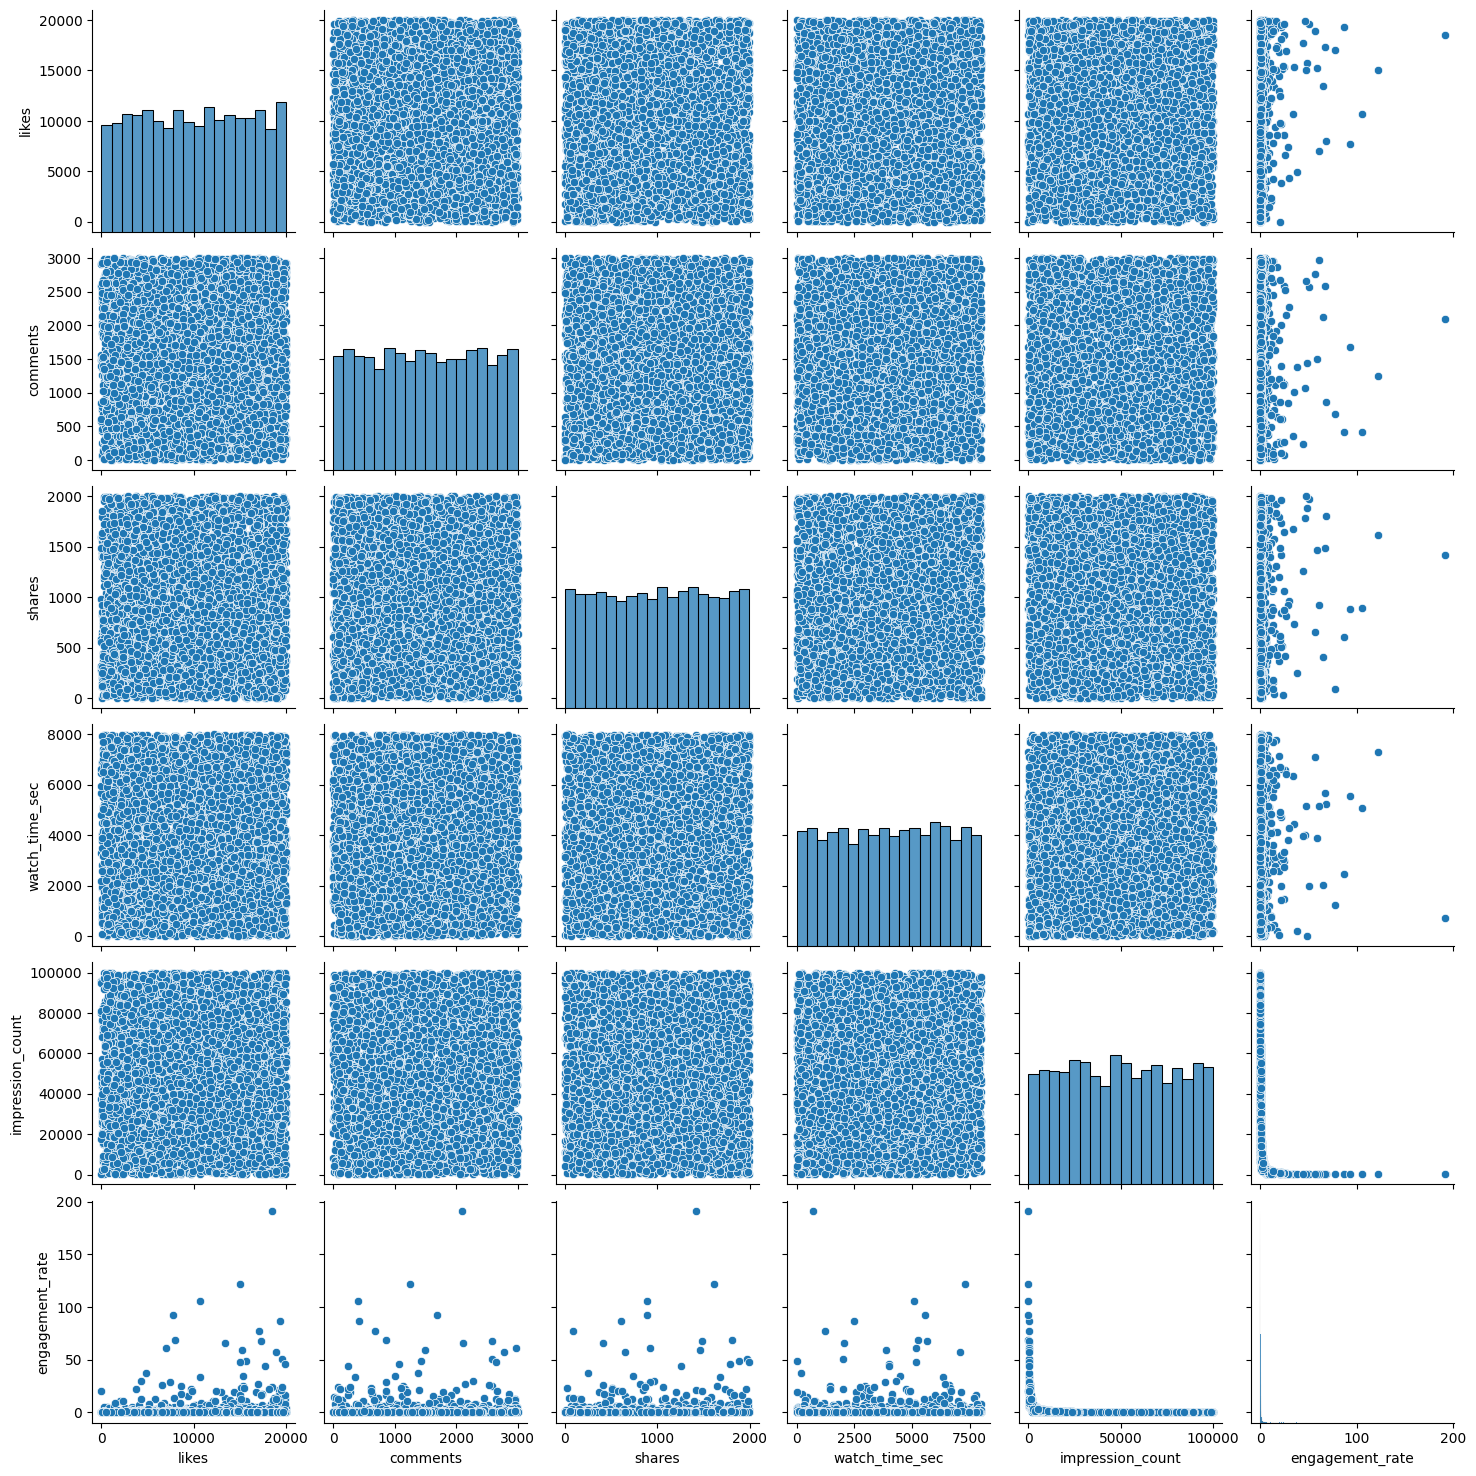

In [80]:
numeric_cols = ['likes', 'comments', 'shares',
                'watch_time_sec', 'impression_count','engagement_rate']

sns.pairplot(df[numeric_cols])
plt.show()

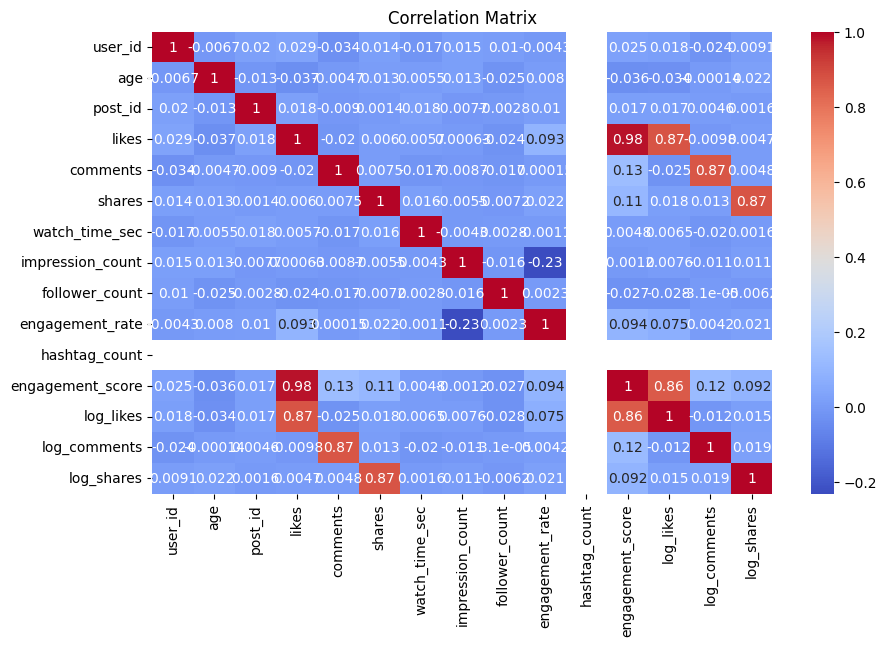

In [81]:
plt.figure(figsize=(10,6))

corr_matrix = df.select_dtypes(include='number').corr()

sns.heatmap(corr_matrix,
            annot=True,cmap='coolwarm')

plt.title("Correlation Matrix")
plt.show()

# Notes:

Created a Count Plot to show the number of posts for each post type.

Created a Bar Plot to compare average likes across post categories.

Created a Violin Plot to analyze follower count distributions by sentiment.

Created a Pair Plot to study relationships among numeric features.

Used Seaborn functions to create attractive and informative statistical visualizations.

Added titles and axis labels to improve readability and interpretation.

# ●	Plotly (Interactive)

○	Interactive line chart/bar chart/bubble/scatter chart



In [84]:
import plotly.express as px

In [85]:
daily_engagement = df.groupby(
    df['posted_at'].dt.date)['engagement_rate'].mean().reset_index()

fig = px.line(daily_engagement,x='posted_at',y='engagement_rate',title='Daily Engagement Trend')

fig.show()

In [86]:
avg_likes = df.groupby('post_type')['likes'].mean().reset_index()

fig = px.bar(
    avg_likes,
    x='post_type',
    y='likes',
    color='post_type',
    title='Average Likes by Post Type')

fig.show()

In [87]:
fig = px.scatter(
    df,
    x='impression_count',
    y='likes',
    color='post_type',
    title='Likes vs Impressions')

fig.show()

Notes:

Used Plotly Express to create interactive charts.

Created a Line Chart to show daily engagement trends.

Created a Bar Chart to compare average likes by post type.

Created a Scatter Plot to analyze the relationship between likes and impressions.

Plotly charts provide interactive features such as zooming, panning, and hover information.

Interactive visualizations help explore social media engagement patterns more effectively.

# ❖	Final Insights should Include following analysis

●	Content Performance

○	Which post types have highest engagement?

○	Best-performing content category?

○	Which countries have highest avg engagement rate?

●	User Trends

○	How age affects engagement

○	Performance difference for verified accounts



In [88]:
df.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)

,engagement_rate
post_type,
video,1.122365
text,1.064549
image,0.895646
reel,0.783047


In [89]:
df.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)

,engagement_rate
post_category,
food,1.358628
tech,1.160475
lifestyle,1.091019
music,0.888803
fitness,0.865628
education,0.844222
fashion,0.807109
travel,0.702223


In [90]:
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

,engagement_rate
country,
Brazil,1.540704
Australia,1.324339
France,1.146402
UAE,1.112352
Canada,0.916659
UK,0.850966
Japan,0.769623
Germany,0.759000
India,0.655005


In [91]:
df.groupby('age')['engagement_rate'].mean()

,engagement_rate
age,
13,0.455583
14,1.003067
15,0.714170
16,1.226848
17,0.858763
18,0.888391
19,0.676687
20,0.515541
21,0.452752


In [92]:
df.groupby('is_verified')['engagement_rate'].mean()

,engagement_rate
is_verified,
False,0.954744
True,1.054250


# Notes:

Analyzed average engagement rates for different post types.

Identified the content category with the highest engagement.

Compared engagement rates across countries.

Studied the relationship between age and engagement.

Compared engagement performance of verified and non-verified accounts.

Used groupby() and aggregation functions to generate insights.

Identified audience preferences and high-performing content.

Generated findings that can help improve social media content strategy.

# Behavioral Insights

●	Best time of day for impressions

●	Device type impact on watch time

# Sentiment Analysis

●	Which sentiment performs best

●	Behavior of negative/neutral sentiment posts




In [93]:
df['hour'] = df['posted_at'].dt.hour

In [94]:
best_time = df.groupby('hour')['impression_count'].mean().sort_values(ascending=False)

print(best_time)

hour
0    50013.7328
Name: impression_count, dtype: float64


In [95]:
device_watchtime = df.groupby('device_type')['watch_time_sec'].mean()

print(device_watchtime)

device_type
desktop    3974.792521
mobile     4087.830760
tablet     3979.736429
Name: watch_time_sec, dtype: float64


In [96]:
sentiment_performance = df.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False)

print(sentiment_performance)

sentiment
negative    1.015169
neutral     0.973683
positive    0.937632
Name: engagement_rate, dtype: float64


In [97]:
df.groupby('sentiment')[['likes', 'comments', 'shares',
                         'engagement_rate']].mean()

,likes,comments,shares,engagement_rate
sentiment,,,,
negative,10170.19778,1503.008073,1007.58224,1.015169
neutral,9960.467937,1537.813333,1001.038095,0.973683
positive,10163.190633,1481.506163,1000.470008,0.937632


# Notes:

# Behavioral Insights

Extracted posting hours from the posted_at column.

Calculated average impressions by hour to find the best posting time.

Compared average watch time across different device types.

Identified which devices generate the highest watch time.

# Sentiment Analysis

Calculated average engagement rate for each sentiment category.

Identified the best-performing sentiment based on engagement.

Compared likes, comments, shares, and engagement rates of negative and neutral posts.

Analyzed how audience interaction varies across different sentiment types.

Used results to understand content effectiveness and user behavior.

# conclusion

This project successfully analyzed social media engagement data using Python libraries such as Pandas, NumPy, Matplotlib, Seaborn, and Plotly.

The dataset was cleaned, transformed, and explored through statistical analysis and visualizations to identify patterns in user engagement.

Key insights were generated regarding content performance, audience behavior, sentiment impact, posting trends, and device usage. The analysis demonstrated how data-driven techniques can help improve content strategies, increase engagement, and support better decision-making in social media marketing.